In [1]:
import json
import pickle
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm

from itertools import combinations
from xgboost import XGBClassifier
from sklearn.model_selection import BaseCrossValidator, ParameterGrid
from sklearn.metrics import (
    accuracy_score, classification_report, f1_score, recall_score, precision_score,
    roc_auc_score, average_precision_score, roc_curve, log_loss
)

In [2]:
# ============================================
# Paths & factor pairs
# ============================================
# Alternate machine path (SARB laptop):
# BASE_DIR = Path('C:/Users/p528552/OneDrive - South African Reserve Bank/Documents/1. MEng - Data Science/1. Project_2025/Data/factor_timing/legacy')
BASE_DIR = Path('C:/Users/ccwis/OneDrive/Documents/1. MEng - Data Science/Project/factor_timing/legacy')

DATA_DIR = BASE_DIR / 'data_input'
OUTPUT_DIR = BASE_DIR / 'results' / 'model_outputs'
PROBS_DIR = OUTPUT_DIR / 'probs'
ARTIFACT_DIR = OUTPUT_DIR / 'artifacts'
SHAP_DIR = OUTPUT_DIR / 'shap'
METRICS_PATH = OUTPUT_DIR / 'metrics_summary.csv'

for _dir in (PROBS_DIR, ARTIFACT_DIR, SHAP_DIR):
    _dir.mkdir(parents=True, exist_ok=True)

# Every factor pair this pipeline runs for a given model.
FACTOR_PAIRS = ['Momentum_vs_Value', 'Momentum_vs_Quality', 'Value_vs_Quality']

In [3]:
# ============================================
# Data loading (parameterized by factor pair)
# ============================================
def load_data(pair):
    df_factor = pd.read_csv(DATA_DIR / 'labeled_relative_factor_returns.csv', parse_dates=['Date'])
    df_factor = df_factor[['Date', f'{pair}_trend']]
    df_factor = df_factor.set_index('Date')

    df = pd.read_csv(DATA_DIR / 'lagged_data.csv', parse_dates=['Date'])
    df = df.set_index('Date')

    data = pd.concat([df, df_factor], axis=1, join='inner')
    # Trend scanning needs returns out to t+10, so the final ~10 dates have
    # no computable label. ffill() would manufacture them from the last known
    # label, putting fabricated targets inside the OOS block -- drop instead.
    data = data.dropna(subset=[f'{pair}_trend'])
    # Unified missing-value policy across all three models.
    return data.ffill().bfill()

In [4]:
# ========================
# Phase 1: Combinatorial Purged CV
# ========================

CV_SPLITS = 5
CV_TEST_SPLITS = 2       # C(5,2) = 10 folds. k=1 collapsed CPCV to plain
                         # 5-fold purged CV with one backtest path.
PURGE_GAP = 12
FINAL_TEST_POINTS = 156   # 3 years of unseen data


class CombinatorialPurgedCV(BaseCrossValidator):
    """Purged Combinatorial Cross-Validation (De Prado style)."""

    def __init__(self, n_splits=CV_SPLITS, n_test_splits=CV_TEST_SPLITS, purge_gap=PURGE_GAP):
        self.n_splits = n_splits
        self.n_test_splits = n_test_splits
        self.purge_gap = purge_gap

    def split(self, X, y=None, groups=None):
        n_samples = len(X)
        fold_size = n_samples // self.n_splits
        indices = np.arange(n_samples)

        # Create fold boundaries
        fold_boundaries = [(i * fold_size, (i + 1) * fold_size) for i in range(self.n_splits)]
        fold_boundaries[-1] = (fold_boundaries[-1][0], n_samples)

        # Generate test fold combinations
        for test_fold_indices in combinations(range(self.n_splits), self.n_test_splits):
            test_mask = np.zeros(n_samples, dtype=bool)

            # Collect test indices
            for fold_idx in test_fold_indices:
                start, end = fold_boundaries[fold_idx]
                test_mask[start:end] = True

            # Train mask starts as complement
            train_mask = ~test_mask

            # Purge around each selected test fold
            for fold_idx in test_fold_indices:
                start, end = fold_boundaries[fold_idx]

                # purge before
                train_mask[max(0, start - self.purge_gap): start] = False
                # purge after
                train_mask[end: min(n_samples, end + self.purge_gap)] = False

            yield indices[train_mask], indices[test_mask]

    def get_n_splits(self, X=None, y=None, groups=None):
        from math import comb
        return comb(self.n_splits, self.n_test_splits)

    def group_bounds(self, n_samples):
        """(start, end) of each chronological group; the last takes the remainder."""
        size = n_samples // self.n_splits
        bounds = [(i * size, (i + 1) * size) for i in range(self.n_splits)]
        bounds[-1] = (bounds[-1][0], n_samples)
        return bounds

    def backtest_paths(self):
        """For each back-test path, the split whose held-out predictions supply each group.

        Every group is held out in C(N-1, k-1) splits; path j takes the j-th of them in
        split order, giving phi[N, k] = C(N-1, k-1) paths, each covering the whole sample
        out of sample (Lopez de Prado, 2018, ch. 12).
        """
        splits = list(combinations(range(self.n_splits), self.n_test_splits))
        holding = [[sp for sp, test in enumerate(splits) if g in test] for g in range(self.n_splits)]
        return [[holding[g][j] for g in range(self.n_splits)] for j in range(len(holding[0]))]


def held_out_vector(n_samples, test_idx, probs):
    """Full-length vector with a split's held-out probabilities in place, NaN elsewhere."""
    out = np.full(n_samples, np.nan)
    out[test_idx] = probs
    return out


def path_aucs(cv, y, split_probs):
    """ROC-AUC of every back-test path, assembled from the splits' held-out predictions."""
    bounds = cv.group_bounds(len(y))
    aucs = []
    for path in cv.backtest_paths():
        pred = np.full(len(y), np.nan)
        for group, split_no in enumerate(path):
            start, end = bounds[group]
            pred[start:end] = split_probs[split_no][start:end]
        assert not np.isnan(pred).any(), "a back-test path is missing held-out predictions"
        aucs.append(roc_auc_score(y, pred))
    return aucs

In [5]:
def window_signature(X):
    """
    Create a stable, compact signature for a rolling window
    based on its mean and std across features.
    Used for hyperparameter caching.
    """
    import hashlib
    stats = np.concatenate([X.mean(axis=0), X.std(axis=0)])
    stats_bytes = stats.tobytes()
    return hashlib.sha1(stats_bytes).hexdigest()

In [6]:
def tune_hyperparameters(X, y, return_grid=False, verbose=True):
    """Grid search over CPCV splits; back-test path AUCs are recorded for reporting."""
    cv = CombinatorialPurgedCV()

    # Revised grid. The previous one searched no regularisation parameters at
    # all and selected learning_rate=0.5 with 500 trees on every pair, which
    # memorises the training window. base_score (3.0% of CV variance) and
    # colsample_bytree (1.0%) dropped as inert; min_child_weight and
    # reg_lambda added. 162 configs vs 243.
    param_grid = {
        'learning_rate':    [0.01, 0.03, 0.1],
        'max_depth':        [2, 3, 4],
        'min_child_weight': [5, 10, 20],
        'reg_lambda':       [1, 10, 100, 1000],
        'subsample':        [0.6, 0.8]
    }

    best_score, best_params = -np.inf, None
    rows = []

    if verbose:
        print(f"Testing {len(ParameterGrid(param_grid))} parameter combinations...")

    for params in ParameterGrid(param_grid):

        fold_scores, split_probs = [], []

        for train_idx, test_idx in cv.split(X, y):
            X_train, X_test = X[train_idx], X[test_idx]
            y_train, y_test = y[train_idx], y[test_idx]

            model = XGBClassifier(
                objective='binary:logistic',
                eval_metric='logloss',
                n_estimators=500,
                n_jobs=1,        # subsample's RNG stream varies with
                random_state=0,  # thread count -- pin both to reproduce
                **params
            )

            model.fit(X_train, y_train, verbose=False)

            # IMPORTANT: use probabilities, not class labels
            y_prob = model.predict_proba(X_test)[:, 1]
            score = roc_auc_score(y_test, y_prob)
            fold_scores.append(float(score))
            split_probs.append(held_out_vector(len(y), test_idx, y_prob))

        # Selection score: mean ROC-AUC over the ten splits. The back-test
        # paths pool predictions from models fitted on different groups, and
        # holding a group out moves the training base rate against that
        # group's own, so an intercept-only model scores about 0.44 on the
        # paths. Path AUCs are recorded for reporting, not used for selection.
        mean_auc = np.mean(fold_scores)
        p_aucs = path_aucs(cv, y, split_probs)

        rows.append({
            **params,
            "mean_auc": mean_auc,            # mean split AUC (selection score)
            "std_auc": np.std(fold_scores, ddof=1),
            "min_auc": np.min(fold_scores),
            "max_auc": np.max(fold_scores),
            "fold_aucs": fold_scores,
            "mean_path_auc": np.mean(p_aucs),
            "path_aucs": p_aucs              # back-test path AUCs (reporting)
        })

        if mean_auc > best_score:
            best_score, best_params = mean_auc, params
            if verbose:
                print(f"New best params: {best_params} (AUC: {best_score:.3f})")

    grid_df = pd.DataFrame(rows).sort_values("mean_auc", ascending=False)

    if verbose:
        print("\n=== Top 5 Parameter Combinations ===")
        for _, r in grid_df.head(5).iterrows():
            row_params = {k: r[k] for k in param_grid}
            print(f"Score: {r['mean_auc']:.3f} | Params: {row_params}")

    if return_grid:
        return best_params, grid_df
    return best_params

In [7]:
def save_artifact(obj, path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)

    if isinstance(obj, pd.DataFrame):
        obj.to_csv(path, index=False)
    elif path.suffix == ".json":
        with open(path, "w") as f:
            json.dump(obj, f, indent=2)
    else:
        with open(path, "wb") as f:
            pickle.dump(obj, f)

In [8]:
def walk_forward_validation(
    X, y, n_test, base_params,
    retune_every=52, lookback=None,  # None = expanding window
    selections=None                  # list that records each retuned parameter set
):
    """
    Rolling-window walk-forward with adaptive hyperparameter tuning
    and hyperparameter caching based on window signatures.
    """

    actuals, predictions, probabilities = [], [], []

    # IMPORTANT
    current_params = base_params.copy()

    hyperparam_cache = {}   # signature -> best_params (dict)

    print(f"\nRunning Rolling-Window Walk-Forward Validation...")
    print(f"Training window = {lookback if lookback else 'expanding (all history)'}")

    for i in tqdm(range(n_test)):
        train_size = len(X) - n_test + i
        if train_size <= 0:
            continue

        # ===== Purge gap =====
        # Trend-scanning labels (span=(1,12)) resolve using returns out to
        # t+10, so training rows within PURGE_GAP of the test point have
        # labels computed from the test period itself. Drop them.
        train_end = train_size - PURGE_GAP
        if train_end <= 0:
            continue

        # Expanding window: train on all history up to the purged end.
        # (lookback=None). Set lookback to an int for a fixed rolling window.
        start = 0 if lookback is None else max(0, train_end - lookback)
        X_train = X[start:train_end]
        y_train = y[start:train_end]

        X_test  = X[train_size:train_size+1]
        y_test  = y[train_size:train_size+1]

        # ======================================================
        # Adaptive hyperparameter tuning + CACHE
        # ======================================================
        if retune_every is not None and i > 0 and i % retune_every == 0:

            sig = window_signature(X_train)

            if sig in hyperparam_cache:
                print(f"\nReusing cached params at step {i}")
                current_params = hyperparam_cache[sig].copy()

            else:
                print(f"\n--- Retuning at step {i}, train_size={train_size} ---")

                new_params = tune_hyperparameters(X_train, y_train)

                current_params = new_params.copy()
                hyperparam_cache[sig] = current_params.copy()

            if selections is not None:
                selections.append({"from_step": i, "n_train": len(y_train), **current_params})


        # ======================================================
        # Fit model with current params
        # ======================================================

        model = XGBClassifier(
            objective='binary:logistic',
            eval_metric='logloss',
            n_estimators=500,
            n_jobs=1,
            random_state=0,
            **current_params
        )

        model.fit(X_train, y_train, verbose=False)

        y_pred = model.predict(X_test)
        y_prob = model.predict_proba(X_test)[:, 1]

        predictions.append(int(y_pred[0]))
        actuals.append(int(y_test[0]))
        probabilities.append(float(y_prob[0]))


    print("\n=== Final Evaluation Results ===")
    print(classification_report(actuals, predictions))

    return (
        np.array(actuals),
        np.array(predictions),
        np.array(probabilities)
    )

In [9]:
# ========================
# Phase 3: Plotting
# ========================
def plot_wfv_results(actuals, predictions, probabilities, pair_label=""):

    # ---- classification metrics
    acc  = accuracy_score(actuals, predictions)
    f1   = f1_score(actuals, predictions)
    rec  = recall_score(actuals, predictions)
    prec = precision_score(actuals, predictions)

    print(f"Walk-forward Performance [{pair_label}]:")
    print(f"Accuracy : {acc:.3f}")
    print(f"F1 Score : {f1:.3f}")
    print(f"Recall   : {rec:.3f}")
    print(f"Precision: {prec:.3f}")

    # ---- probabilistic metrics
    auc    = roc_auc_score(actuals, probabilities)
    pr_auc = average_precision_score(actuals, probabilities)
    ll     = log_loss(actuals, probabilities)

    print(f"ROC AUC :   {auc:.4f}")
    print(f"PR  AUC :   {pr_auc:.4f}")
    print(f"Log Loss:   {ll:.4f}")

    # ---- timeline
    plt.figure(figsize=(12, 6))
    plt.plot(actuals, label='Actual', marker='o',linestyle='None')
    plt.plot(predictions, label='Predicted', marker='x',linestyle='None')
    plt.plot(probabilities, label='Probability', linestyle='--', alpha=0.5)
    plt.title(f'Walk-Forward Validation Results [{pair_label}]')
    plt.legend()
    plt.show()

    # ---- ROC curve
    fpr, tpr, _ = roc_curve(actuals, probabilities)
    plt.figure(figsize=(6, 6))
    plt.plot(fpr, tpr, label=f'ROC AUC = {auc:.3f}')
    plt.plot([0,1],[0,1],'--k')
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(f"ROC Curve [{pair_label}]")
    plt.legend()
    plt.show()

    return {
        "accuracy": acc, "f1": f1, "recall": rec, "precision": prec,
        "roc_auc": auc, "pr_auc": pr_auc, "log_loss": ll,
    }

In [10]:
# ============================================
# Metrics summary — single source of truth for the write-up.
# Re-running a pair updates its row instead of duplicating it.
# ============================================
def append_metrics_row(row):
    row = {"timestamp": datetime.now(timezone.utc).isoformat(), **row}
    new_row = pd.DataFrame([row])
    if METRICS_PATH.exists():
        existing = pd.read_csv(METRICS_PATH)
        existing = existing[~(
            (existing["model"] == row["model"]) & (existing["factor_pair"] == row["factor_pair"])
        )]
        combined = pd.concat([existing, new_row], ignore_index=True)
    else:
        combined = new_row
    combined.to_csv(METRICS_PATH, index=False)

In [11]:
# ============================================
# XGBoost SHAP feature importance (Tree SHAP)
# ============================================
def compute_shap_importance(data, best_params, feature_names, n_test):
    import shap

    X = data.iloc[:, :-1].values
    y = data.iloc[:, -1].values
    X = np.nan_to_num(X, nan=np.nan, posinf=1e10, neginf=-1e10)

    train_end = len(X) - n_test
    X_train_final = X[:train_end]
    y_train_final = y[:train_end]

    final_model = XGBClassifier(
        objective="binary:logistic",
        eval_metric="logloss",
        n_estimators=500,  # must match walk_forward_validation; the xgboost
                           # default (100) explained a different model
        n_jobs=1,
        random_state=0,
        **best_params
    )
    final_model.fit(X_train_final, y_train_final)

    explainer = shap.TreeExplainer(final_model)
    shap_values = explainer.shap_values(X_train_final)

    importance = pd.Series(
        np.abs(shap_values).mean(axis=0),
        index=feature_names
    ).sort_values(ascending=False)

    return importance, shap_values, X_train_final

In [12]:
# ============================================
# Full pipeline for one factor pair
# ============================================
def run_pipeline(pair):
    pair_slug = pair.lower()
    print(f"\n{'='*60}\nFACTOR PAIR: {pair}\n{'='*60}")

    data = load_data(pair)

    X = data.iloc[:, :-1].values
    y = data.iloc[:, -1].values
    feature_names = data.columns[:-1].tolist()

    # Handle inf/NaN (XGBoost handles NaNs natively, but we cap inf)
    X = np.nan_to_num(X, nan=np.nan, posinf=1e10, neginf=-1e10)

    print("=== PHASE 1: INITIAL HYPERPARAMETER TUNING ===")
    # Tune only on pre-test data:
    X_train_full = X[:-FINAL_TEST_POINTS]
    y_train_full = y[:-FINAL_TEST_POINTS]

    best_params, tuning_grid = tune_hyperparameters(X_train_full, y_train_full, return_grid=True)
    save_artifact(tuning_grid, ARTIFACT_DIR / f"xgboost_{pair_slug}_tuning_grid.pkl")
    save_artifact(best_params, ARTIFACT_DIR / f"xgboost_{pair_slug}_best_params.json")

    print("\n=== PHASE 2: ADAPTIVE ROLLING WALK-FORWARD ===")
    selections = [{"from_step": 0, "n_train": len(y_train_full), **best_params}]
    actuals, preds, probs = walk_forward_validation(
        X, y,
        n_test=FINAL_TEST_POINTS,
        base_params=best_params,
        retune_every=52,      # yearly retuning
        lookback=None,        # expanding window
        selections=selections
    )
    save_artifact(selections, ARTIFACT_DIR / f"xgboost_{pair_slug}_walkforward_params.json")

    print("\n=== ADAPTIVE PARAMS RESULTS ===")
    metrics = plot_wfv_results(actuals, preds, probs, pair_label=pair)

    df_probs = pd.DataFrame({
        "Date": data.index[-len(probs):],
        "actual": actuals,
        "prediction": preds,
        "probability": probs,
    }).set_index("Date")
    df_probs.to_csv(PROBS_DIR / f"xgboost_{pair_slug}_probs.csv", index=True)

    shap_importance, shap_values, X_train_final = compute_shap_importance(
        data, best_params, feature_names, FINAL_TEST_POINTS
    )
    shap_importance.head(20).to_csv(SHAP_DIR / f"xgboost_{pair_slug}_shap.csv", index=True)

    append_metrics_row({
        "model": "XGBoost",
        "factor_pair": pair,
        "n_test": FINAL_TEST_POINTS,
        **metrics,
        "best_params": json.dumps(best_params),
    })

    return {
        "pair": pair,
        "best_params": best_params,
        "tuning_grid": tuning_grid,
        "feature_names": feature_names,
        "adaptive": (actuals, preds, probs),
        "shap_importance": shap_importance,
        "shap_values": shap_values,
        "X_train_final": X_train_final,
    }

In [13]:
def plot_pair_diagnostics(result):
    import shap

    pair = result["pair"]

    plt.figure(figsize=(10, 12))
    result["shap_importance"].head(20).plot(kind='barh', color='purple')
    plt.title(f"XGBoost SHAP Global Feature Importance\n(Mean |SHAP|) [{pair}]")
    plt.xlabel("Mean(|SHAP|)")
    plt.gca().invert_yaxis()
    plt.grid(axis='x', linestyle='--', alpha=0.4)
    plt.show()

    shap.summary_plot(result["shap_values"], result["X_train_final"],
                      feature_names=result["feature_names"], plot_type="dot")
    shap.summary_plot(result["shap_values"], result["X_train_final"],
                      feature_names=result["feature_names"], plot_type="bar")


FACTOR PAIR: Momentum_vs_Value
=== PHASE 1: INITIAL HYPERPARAMETER TUNING ===
Testing 216 parameter combinations...


New best params: {'learning_rate': 0.01, 'max_depth': 2, 'min_child_weight': 5, 'reg_lambda': 1, 'subsample': 0.6} (AUC: 0.506)


New best params: {'learning_rate': 0.01, 'max_depth': 2, 'min_child_weight': 5, 'reg_lambda': 10, 'subsample': 0.6} (AUC: 0.510)


New best params: {'learning_rate': 0.01, 'max_depth': 2, 'min_child_weight': 10, 'reg_lambda': 1, 'subsample': 0.6} (AUC: 0.514)


New best params: {'learning_rate': 0.01, 'max_depth': 2, 'min_child_weight': 10, 'reg_lambda': 10, 'subsample': 0.6} (AUC: 0.517)


New best params: {'learning_rate': 0.01, 'max_depth': 3, 'min_child_weight': 10, 'reg_lambda': 1, 'subsample': 0.6} (AUC: 0.519)


... (184 outputs left out)

 99%|█████████▉| 155/156 [29:10<00:00,  1.93it/s]

100%|██████████| 156/156 [29:10<00:00,  1.95it/s]

100%|██████████| 156/156 [29:10<00:00, 11.22s/it]


=== Final Evaluation Results ===
              precision    recall  f1-score   support

           0       0.59      0.52      0.55        71
           1       0.63      0.69      0.66        85

    accuracy                           0.62       156
   macro avg       0.61      0.61      0.61       156
weighted avg       0.61      0.62      0.61       156


=== ADAPTIVE PARAMS RESULTS ===
Walk-forward Performance [Momentum_vs_Value]:
Accuracy : 0.615
F1 Score : 0.663
Recall   : 0.694
Precision: 0.634
ROC AUC :   0.5891
PR  AUC :   0.6106
Log Loss:   0.7588


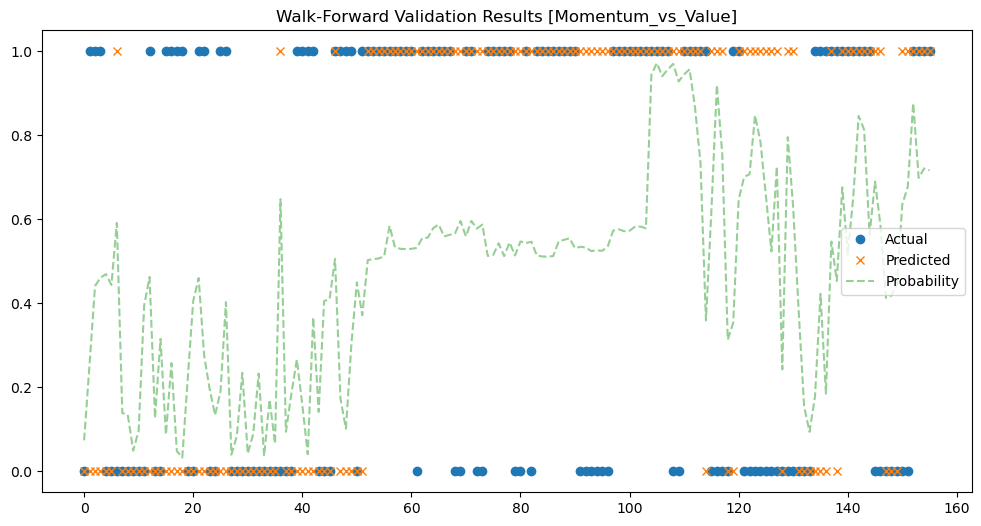

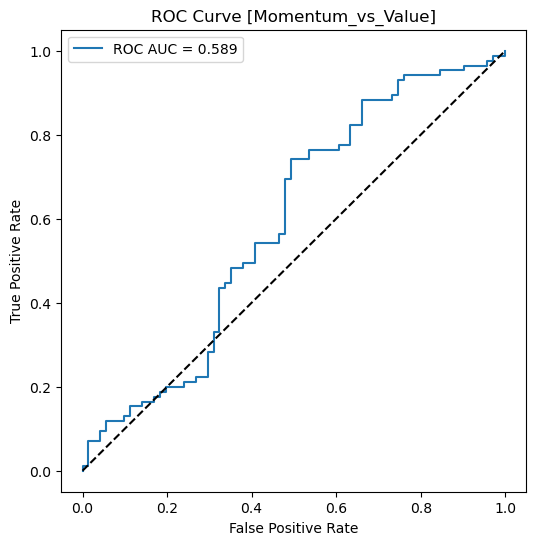

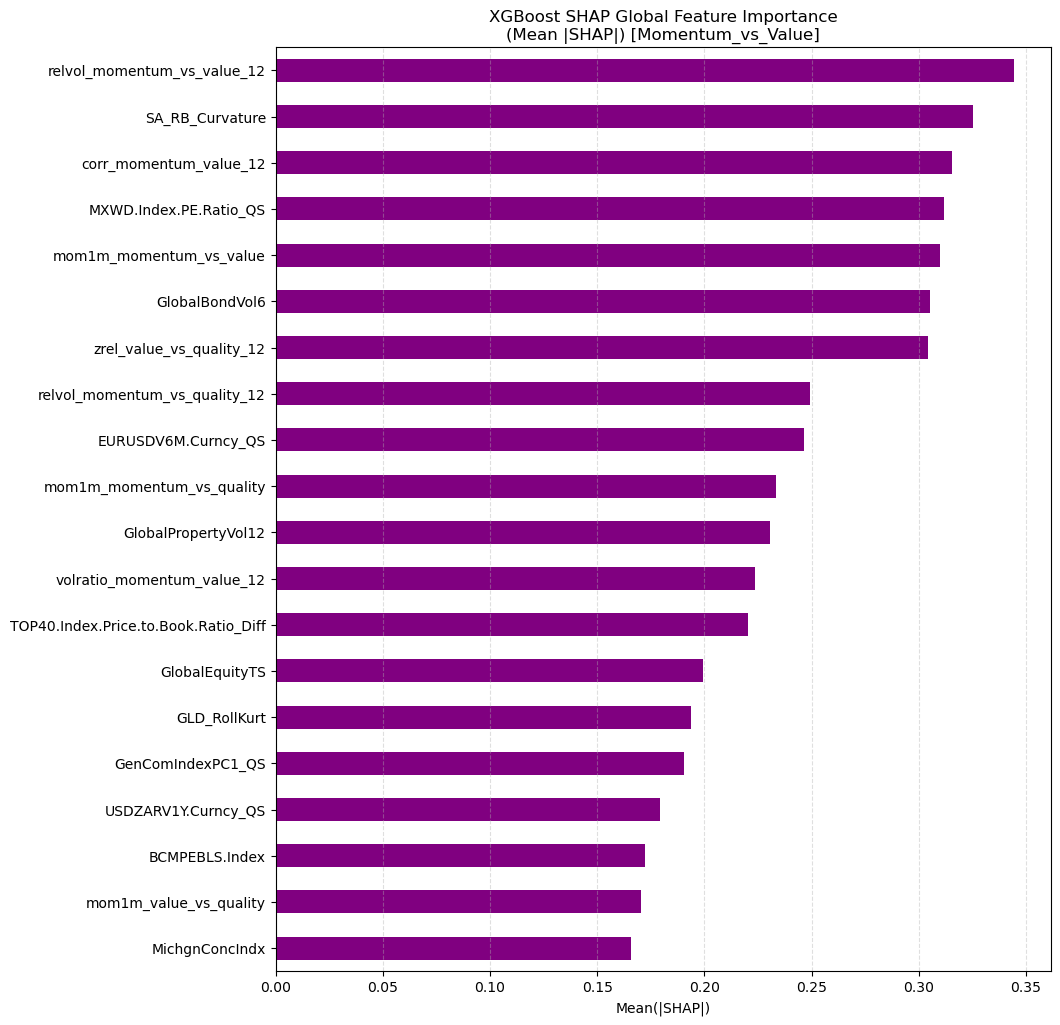

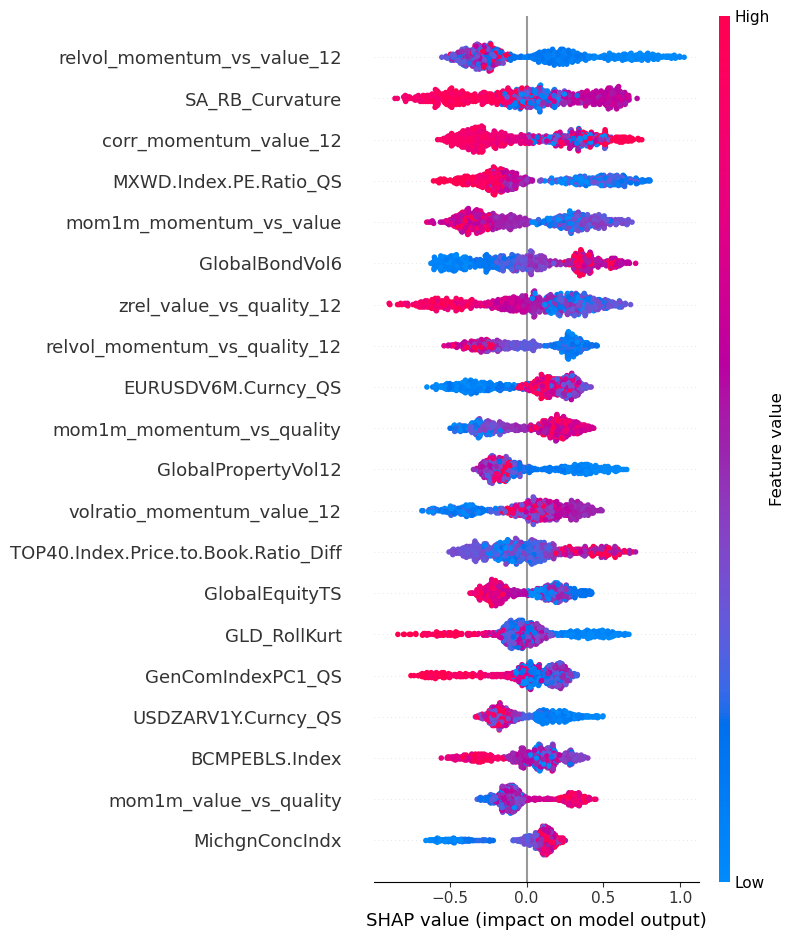

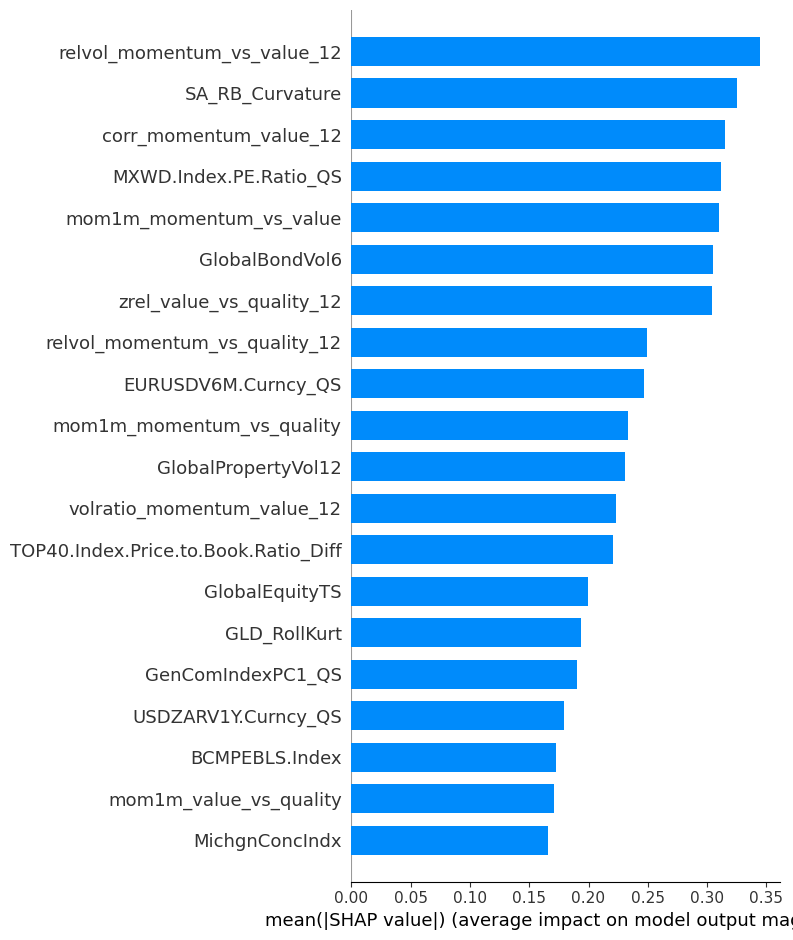


FACTOR PAIR: Momentum_vs_Quality
=== PHASE 1: INITIAL HYPERPARAMETER TUNING ===
Testing 216 parameter combinations...


New best params: {'learning_rate': 0.01, 'max_depth': 2, 'min_child_weight': 5, 'reg_lambda': 1, 'subsample': 0.6} (AUC: 0.509)


New best params: {'learning_rate': 0.01, 'max_depth': 2, 'min_child_weight': 5, 'reg_lambda': 1, 'subsample': 0.8} (AUC: 0.509)


New best params: {'learning_rate': 0.01, 'max_depth': 2, 'min_child_weight': 5, 'reg_lambda': 10, 'subsample': 0.6} (AUC: 0.519)


New best params: {'learning_rate': 0.01, 'max_depth': 2, 'min_child_weight': 10, 'reg_lambda': 1, 'subsample': 0.6} (AUC: 0.522)


New best params: {'learning_rate': 0.01, 'max_depth': 2, 'min_child_weight': 10, 'reg_lambda': 10, 'subsample': 0.6} (AUC: 0.527)


... (183 outputs left out)

 99%|█████████▉| 155/156 [21:45<00:00,  3.96it/s]

100%|██████████| 156/156 [21:45<00:00,  4.06it/s]

100%|██████████| 156/156 [21:45<00:00,  8.37s/it]


=== Final Evaluation Results ===
              precision    recall  f1-score   support

           0       0.52      0.59      0.55        73
           1       0.59      0.52      0.55        83

    accuracy                           0.55       156
   macro avg       0.55      0.55      0.55       156
weighted avg       0.56      0.55      0.55       156


=== ADAPTIVE PARAMS RESULTS ===
Walk-forward Performance [Momentum_vs_Quality]:
Accuracy : 0.551
F1 Score : 0.551
Recall   : 0.518
Precision: 0.589
ROC AUC :   0.5785
PR  AUC :   0.6156
Log Loss:   0.7194


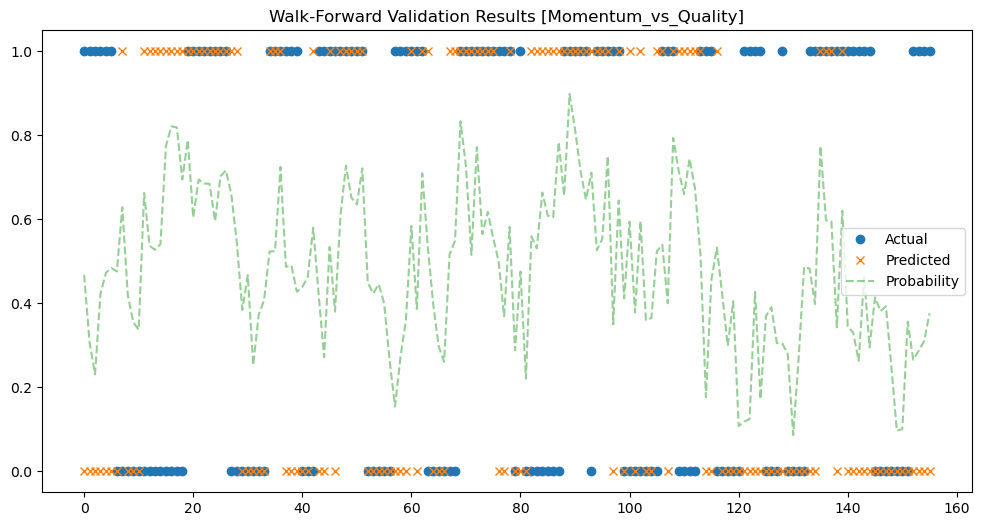

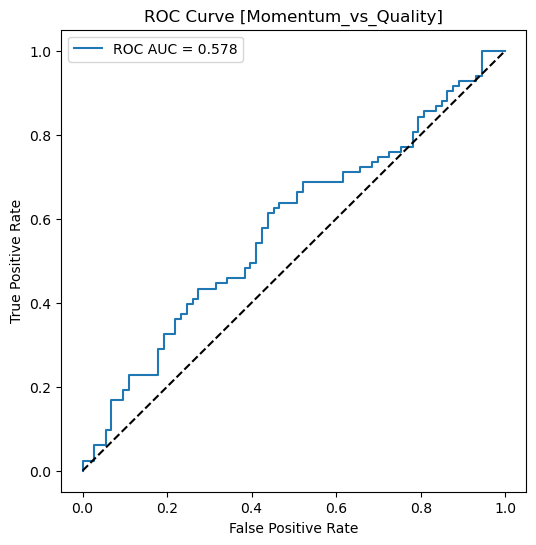

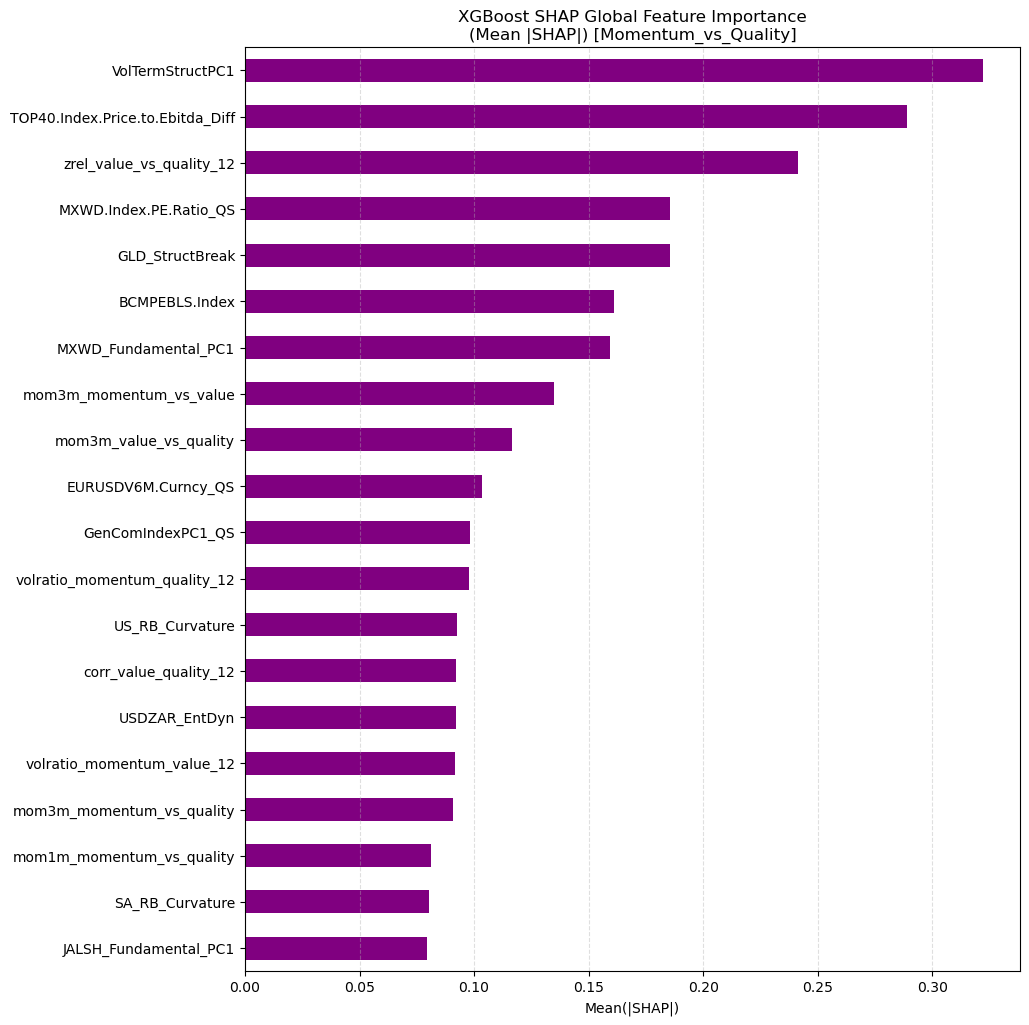

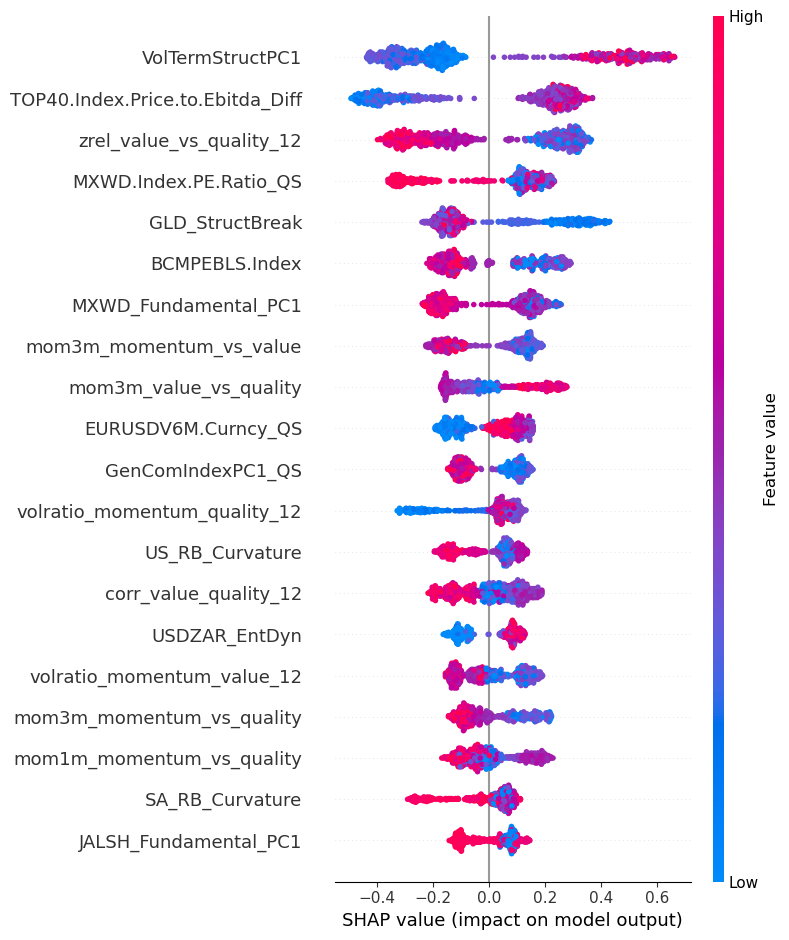

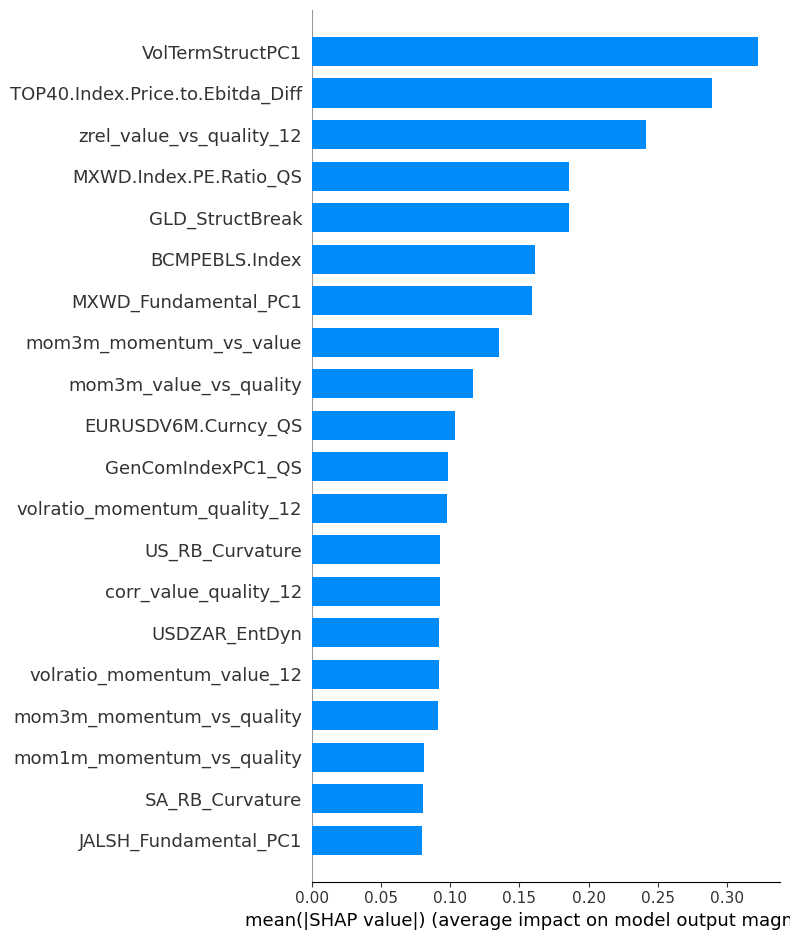


FACTOR PAIR: Value_vs_Quality
=== PHASE 1: INITIAL HYPERPARAMETER TUNING ===
Testing 216 parameter combinations...


New best params: {'learning_rate': 0.01, 'max_depth': 2, 'min_child_weight': 5, 'reg_lambda': 1, 'subsample': 0.6} (AUC: 0.509)


New best params: {'learning_rate': 0.01, 'max_depth': 2, 'min_child_weight': 5, 'reg_lambda': 10, 'subsample': 0.6} (AUC: 0.511)


New best params: {'learning_rate': 0.01, 'max_depth': 2, 'min_child_weight': 5, 'reg_lambda': 10, 'subsample': 0.8} (AUC: 0.512)


New best params: {'learning_rate': 0.01, 'max_depth': 2, 'min_child_weight': 5, 'reg_lambda': 100, 'subsample': 0.6} (AUC: 0.525)


New best params: {'learning_rate': 0.01, 'max_depth': 2, 'min_child_weight': 10, 'reg_lambda': 1000, 'subsample': 0.6} (AUC: 0.525)


... (174 outputs left out)

 99%|█████████▉| 155/156 [28:38<00:00,  3.78it/s]

100%|██████████| 156/156 [28:39<00:00,  3.83it/s]

100%|██████████| 156/156 [28:39<00:00, 11.02s/it]


=== Final Evaluation Results ===
              precision    recall  f1-score   support

           0       0.60      0.07      0.13        82
           1       0.48      0.95      0.64        74

    accuracy                           0.49       156
   macro avg       0.54      0.51      0.38       156
weighted avg       0.54      0.49      0.37       156


=== ADAPTIVE PARAMS RESULTS ===
Walk-forward Performance [Value_vs_Quality]:
Accuracy : 0.487
F1 Score : 0.636
Recall   : 0.946
Precision: 0.479
ROC AUC :   0.5651
PR  AUC :   0.5976
Log Loss:   0.6907


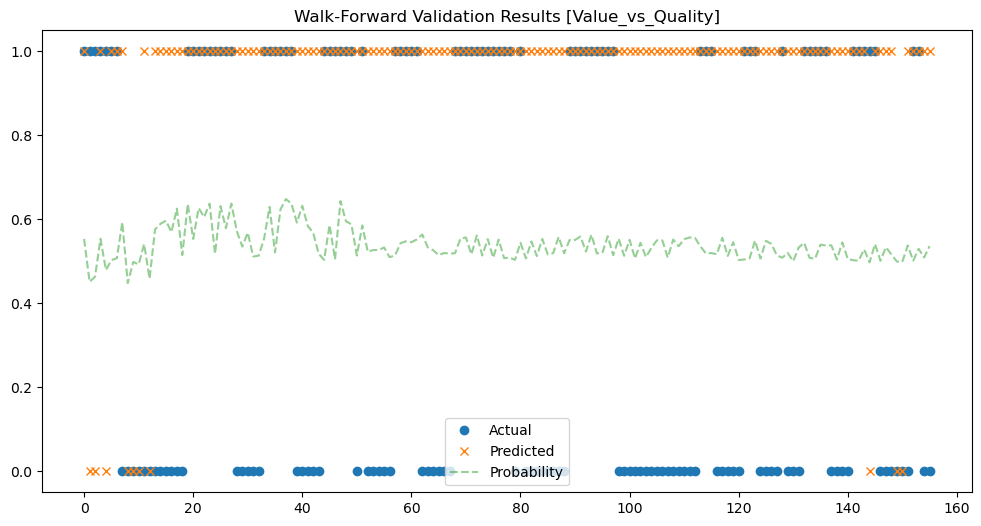

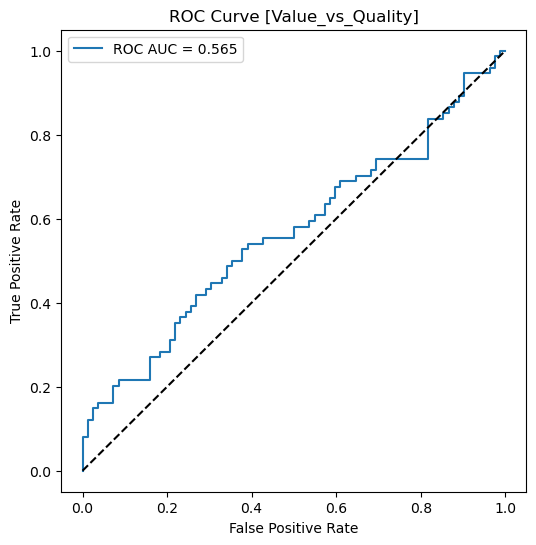

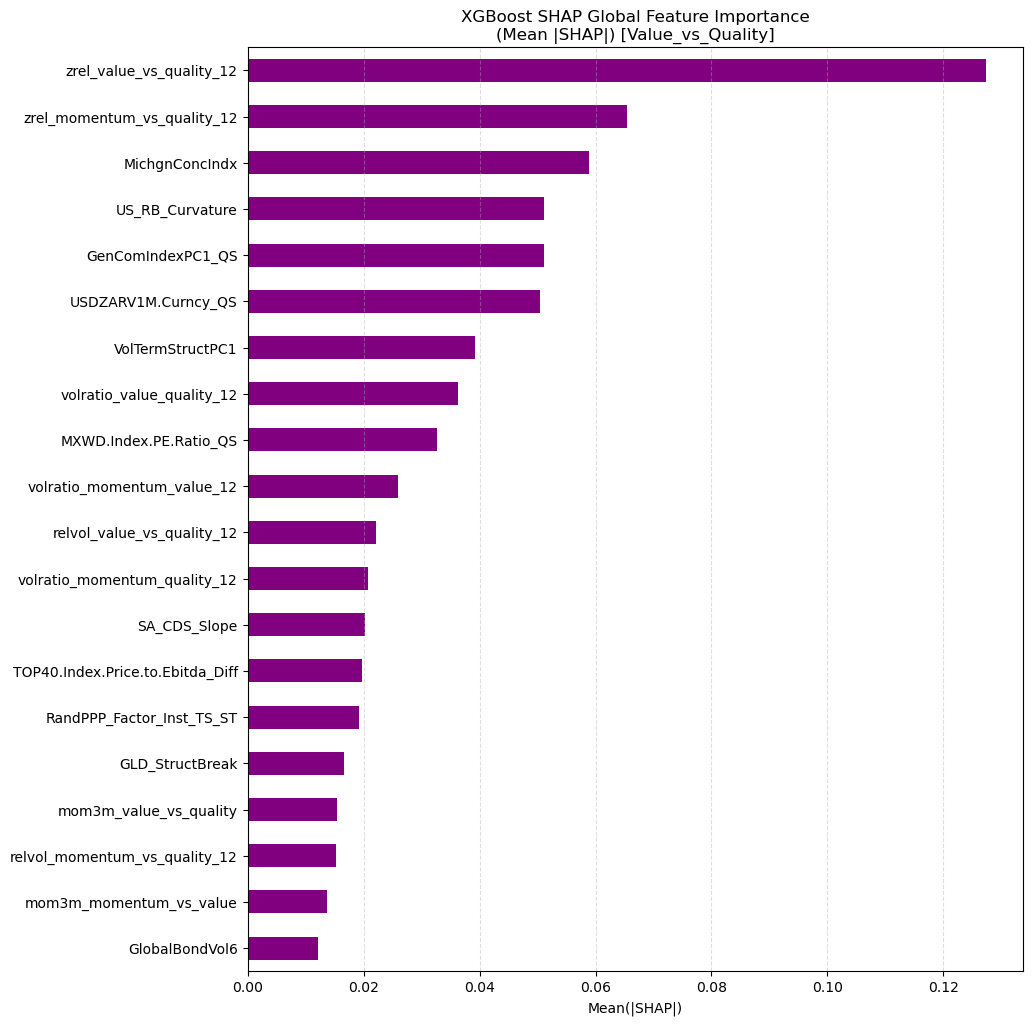

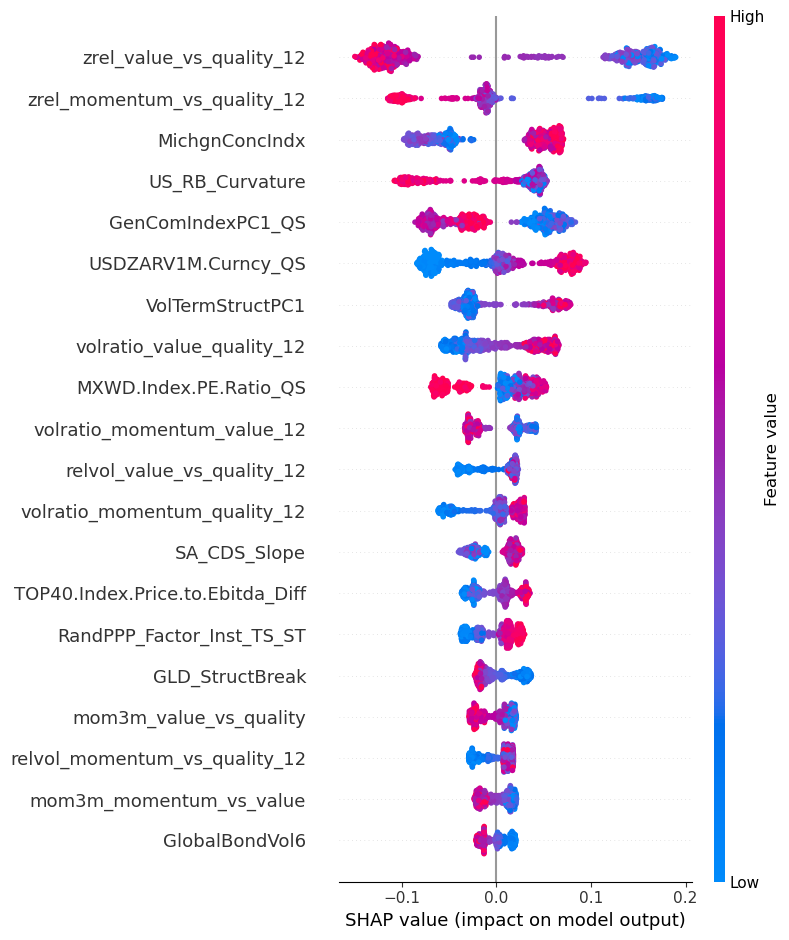

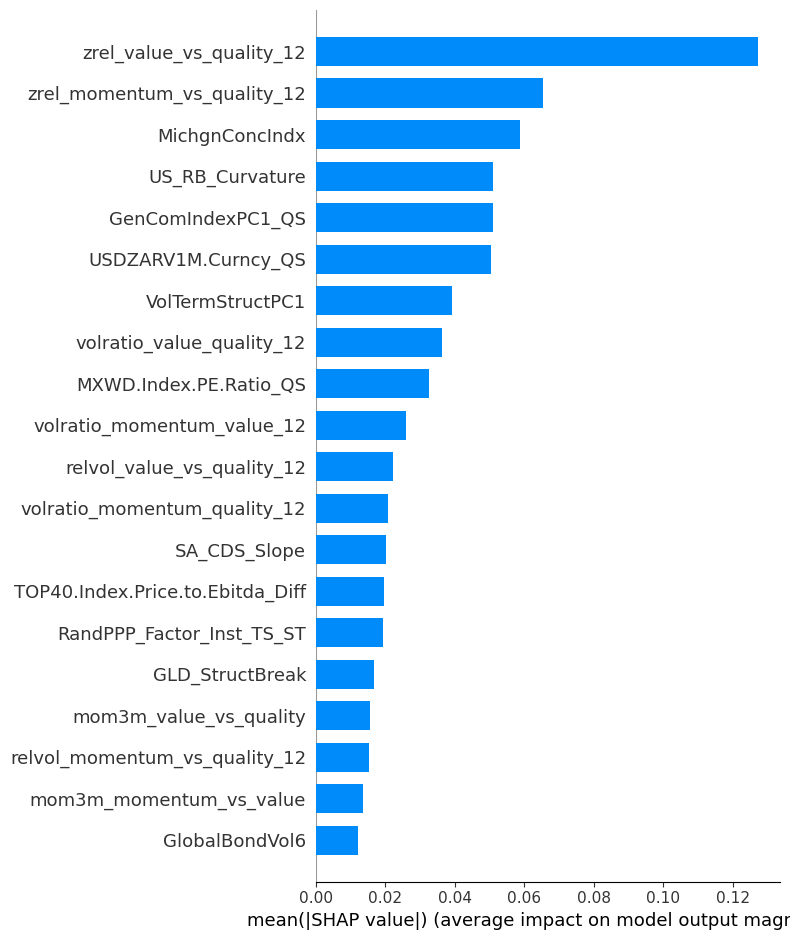


Done. Metrics summary written to: C:\Users\ccwis\OneDrive\Documents\1. MEng - Data Science\Project\factor_timing\legacy\results\model_outputs\metrics_summary.csv


In [14]:
# ============================================
# Run every factor pair
# ============================================
all_results = {}
for pair in FACTOR_PAIRS:
    all_results[pair] = run_pipeline(pair)
    plot_pair_diagnostics(all_results[pair])

print("\nDone. Metrics summary written to:", METRICS_PATH)